# Pet Breed Classification with a Custom CNN

This project trains a custom Convolutional Neural Network to classify ten cat and dog breeds from the Oxford-IIIT Pet Dataset. The model is compared with majority-class and logistic-regression baselines using accuracy and macro-F1.

## 1. Set up the Colab runtime

This section installs the required libraries, fixes the random seed for reproducibility, and confirms that a T4 GPU is available for training.

In [ ]:
!pip -q install scikit-learn matplotlib tqdm

import random
import numpy as np
import torch
import torchvision
from torchvision import datasets

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## 2. Download the dataset and select ten breeds

The Oxford-IIIT Pet Dataset contains 37 cat and dog breeds. This project selects ten visually similar breeds, including Persian, Ragdoll, Birman, Beagle, and two terrier breeds.

In [ ]:
trainval_source = datasets.OxfordIIITPet(
    root="data",
    split="trainval",
    target_types="category",
    download=True
)

test_source = datasets.OxfordIIITPet(
    root="data",
    split="test",
    target_types="category",
    download=True
)

print("Official train/validation images:", len(trainval_source))
print("Official test images:", len(test_source))
print("\nAvailable breeds:")
print(trainval_source.classes)

BREEDS = [
    "Persian",
    "Ragdoll",
    "Birman",
    "Maine Coon",
    "Siamese",
    "Beagle",
    "Basset Hound",
    "American Pit Bull Terrier",
    "Staffordshire Bull Terrier",
    "Pug",
]

class_to_source_id = {
    breed: trainval_source.classes.index(breed)
    for breed in BREEDS
}

source_id_to_project_id = {
    source_id: project_id
    for project_id, source_id in enumerate(class_to_source_id.values())
}

print("Project class mapping:")
for breed, source_id in class_to_source_id.items():
    print(f"{source_id:2d} → {source_id_to_project_id[source_id]} → {breed}")

assert all(breed in trainval_source.classes for breed in BREEDS)
print("\nAll 10 selected breeds were found.")

Project class mapping:
23 → 0 → Persian
26 → 1 → Ragdoll
 6 → 2 → Birman
20 → 3 → Maine Coon
32 → 4 → Siamese
 4 → 5 → Beagle
 3 → 6 → Basset Hound
 2 → 7 → American Pit Bull Terrier
34 → 8 → Staffordshire Bull Terrier
25 → 9 → Pug

All 10 selected breeds were found.


## 3. Inspect selected-breed examples

Before training, this section displays one image from each selected breed. Visual inspection helps confirm that labels and images were loaded correctly.

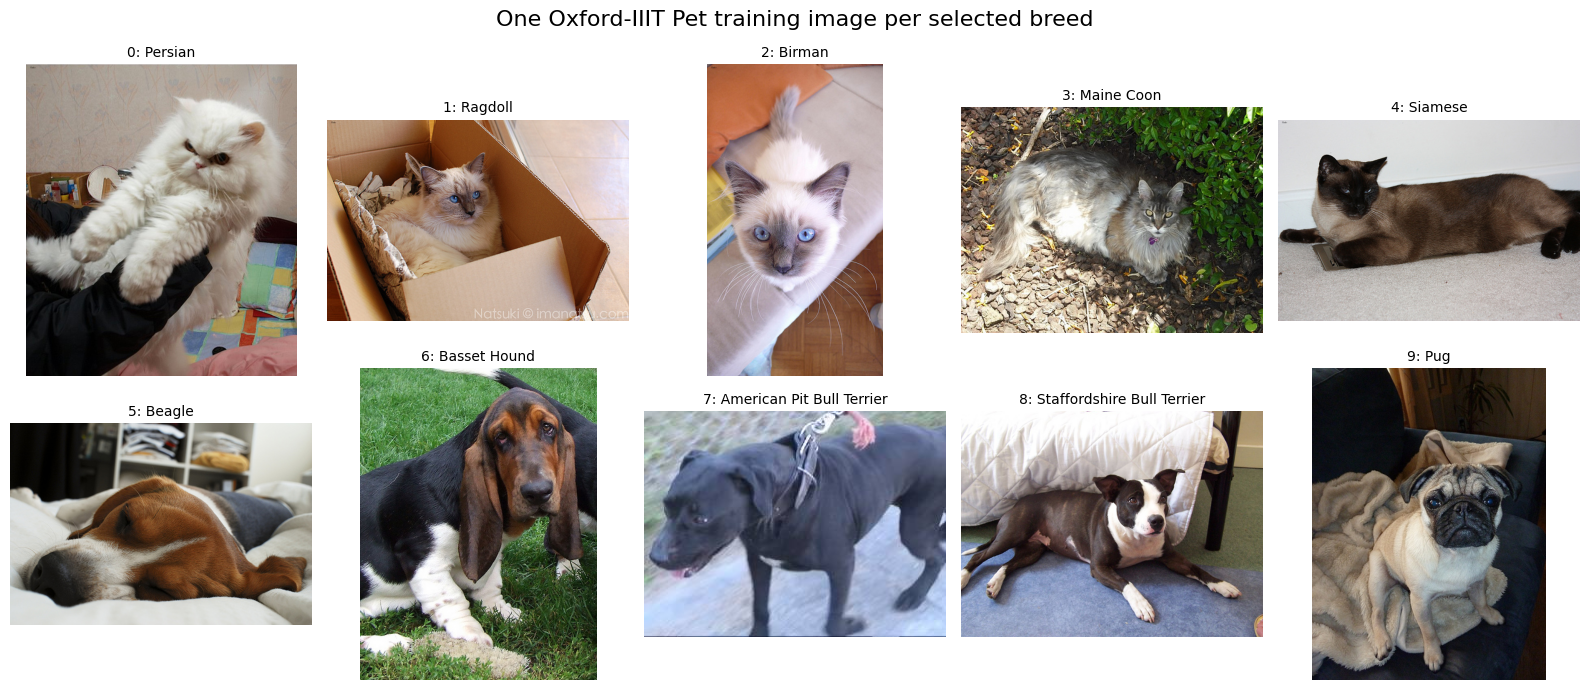

In [ ]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.flatten()

source_labels = np.array(trainval_source._labels)

for project_id, breed in enumerate(BREEDS):
    source_id = class_to_source_id[breed]
    matching_indices = np.where(source_labels == source_id)[0]

    chosen_index = rng.choice(matching_indices)
    image, original_label = trainval_source[chosen_index]

    axes[project_id].imshow(image)
    axes[project_id].set_title(f"{project_id}: {breed}", fontsize=10)
    axes[project_id].axis("off")

    assert original_label == source_id

plt.suptitle("One Oxford-IIIT Pet training image per selected breed", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
import json

IMAGE_SIZE = 64
CACHE_PATH = Path("data/pets10_64_split.npz")

all_images = []
all_labels = []

# Pool the released trainval and test portions, then make our own fixed split.
for split_name, source in [
    ("official trainval", trainval_source),
    ("official test", test_source),
]:
    for image, source_label in tqdm(source, desc=f"Reading {split_name}"):
        if source_label not in source_id_to_project_id:
            continue

        image = image.convert("RGB").resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.BILINEAR
        )

        all_images.append(np.asarray(image, dtype=np.uint8))
        all_labels.append(source_id_to_project_id[source_label])

images = np.stack(all_images)
labels = np.asarray(all_labels, dtype=np.int64)

all_indices = np.arange(len(labels))

train_indices, remaining_indices = train_test_split(
    all_indices,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

val_indices, test_indices = train_test_split(
    remaining_indices,
    test_size=0.50,
    stratify=labels[remaining_indices],
    random_state=SEED
)

assert len(set(train_indices) & set(val_indices)) == 0
assert len(set(train_indices) & set(test_indices)) == 0
assert len(set(val_indices) & set(test_indices)) == 0
assert len(train_indices) + len(val_indices) + len(test_indices) == len(labels)

# Calculate normalization statistics from training images only.
train_pixels = images[train_indices].astype(np.float32) / 255.0
train_mean = train_pixels.mean(axis=(0, 1, 2))
train_std = train_pixels.std(axis=(0, 1, 2))

# Cache images, labels, and split indices locally. data/ is git-ignored.
np.savez_compressed(
    CACHE_PATH,
    images=images,
    labels=labels,
    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_indices,
    class_names=np.array(BREEDS),
    train_mean=train_mean,
    train_std=train_std,
)

summary = {
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "class_names": BREEDS,
    "total_images": int(len(labels)),
    "train_images": int(len(train_indices)),
    "validation_images": int(len(val_indices)),
    "test_images": int(len(test_indices)),
    "train_mean": train_mean.tolist(),
    "train_std": train_std.tolist(),
}

Path("reports").mkdir(exist_ok=True)
with open("reports/split_summary.json", "w") as file:
    json.dump(summary, file, indent=2)

print(json.dumps(summary, indent=2))
print(f"\nSaved local cache: {CACHE_PATH}")

Reading official trainval:   0%|          | 0/3680 [00:00<?, ?it/s]

Reading official test:   0%|          | 0/3669 [00:00<?, ?it/s]

{
  "seed": 42,
  "image_size": 64,
  "class_names": [
    "Persian",
    "Ragdoll",
    "Birman",
    "Maine Coon",
    "Siamese",
    "Beagle",
    "Basset Hound",
    "American Pit Bull Terrier",
    "Staffordshire Bull Terrier",
    "Pug"
  ],
  "total_images": 1988,
  "train_images": 1391,
  "validation_images": 298,
  "test_images": 299,
  "train_mean": [
    0.4820140302181244,
    0.4492906332015991,
    0.3960590660572052
  ],
  "train_std": [
    0.2537180185317993,
    0.2511528730392456,
    0.2605602443218231
  ]
}

Saved local cache: data/pets10_64_split.npz


## 5. Establish validation baselines

A majority-class predictor and logistic regression on downsampled grayscale pixels provide simple reference points. The custom CNN should substantially outperform both baselines.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import torch.nn.functional as F

cache = np.load(CACHE_PATH)

images = cache["images"]
labels = cache["labels"]

train_indices = cache["train_indices"]
val_indices = cache["val_indices"]

# Baseline 1: predict the most common training class every time.
majority_class = np.bincount(labels[train_indices]).argmax()
majority_predictions = np.full(len(val_indices), majority_class)

majority_accuracy = accuracy_score(labels[val_indices], majority_predictions)
majority_f1 = f1_score(
    labels[val_indices],
    majority_predictions,
    average="macro",
    zero_division=0
)

# Baseline 2: logistic regression on 32x32 grayscale pixels.
image_tensor = torch.from_numpy(images).permute(0, 3, 1, 2).float() / 255.0

gray_tensor = (
    0.299 * image_tensor[:, 0:1]
    + 0.587 * image_tensor[:, 1:2]
    + 0.114 * image_tensor[:, 2:3]
)

small_gray = F.interpolate(
    gray_tensor,
    size=(32, 32),
    mode="bilinear",
    align_corners=False
)

features = small_gray.flatten(start_dim=1).numpy()

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED,
    n_jobs=-1
)

logistic_model.fit(features[train_indices], labels[train_indices])

logistic_predictions = logistic_model.predict(features[val_indices])

logistic_accuracy = accuracy_score(labels[val_indices], logistic_predictions)
logistic_f1 = f1_score(
    labels[val_indices],
    logistic_predictions,
    average="macro",
    zero_division=0
)

baseline_results = {
    "split_used": "validation only",
    "majority_class": BREEDS[majority_class],
    "majority_accuracy": float(majority_accuracy),
    "majority_macro_f1": float(majority_f1),
    "logistic_regression_accuracy": float(logistic_accuracy),
    "logistic_regression_macro_f1": float(logistic_f1),
}

with open("reports/validation_baselines.json", "w") as file:
    json.dump(baseline_results, file, indent=2)

print(json.dumps(baseline_results, indent=2))

{
  "split_used": "validation only",
  "majority_class": "Persian",
  "majority_accuracy": 0.10067114093959731,
  "majority_macro_f1": 0.018292682926829267,
  "logistic_regression_accuracy": 0.18456375838926176,
  "logistic_regression_macro_f1": 0.17771998432906003
}


## 6. Build the image data pipeline

Training images use crop, flip, and colour-jitter augmentation in the augmentation experiment. Validation and test images are normalized but never augmented.

In [ ]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

train_mean = cache["train_mean"].tolist()
train_std = cache["train_std"].tolist()

train_transform = transforms.Compose([
    transforms.RandomCrop(IMAGE_SIZE, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=train_mean, std=train_std),
])

evaluation_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=train_mean, std=train_std),
])

class PetDataset(Dataset):
    def __init__(self, images, labels, indices, transform):
        self.images = images
        self.labels = labels
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        original_index = self.indices[index]

        image = Image.fromarray(
            self.images[original_index],
            mode="RGB"
        )

        label = int(self.labels[original_index])

        return self.transform(image), label

train_dataset = PetDataset(
    images, labels, train_indices, train_transform
)

val_dataset = PetDataset(
    images, labels, val_indices, evaluation_transform
)

test_dataset = PetDataset(
    images, labels, cache["test_indices"], evaluation_transform
)

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

batch_images, batch_labels = next(iter(train_loader))

print("Training images:", batch_images.shape)
print("Training labels:", batch_labels.shape)
print("Example labels:", batch_labels[:10].tolist())
print("Image value range after normalization:",
      round(batch_images.min().item(), 3),
      "to",
      round(batch_images.max().item(), 3))

assert batch_images.shape == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
assert batch_labels.shape == (BATCH_SIZE,)
assert batch_labels.min() >= 0
assert batch_labels.max() < len(BREEDS)

print("\nData loader checks passed.")

/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(


Training images: torch.Size([64, 3, 64, 64])
Training labels: torch.Size([64])
Example labels: [4, 7, 1, 8, 7, 2, 0, 0, 2, 4]
Image value range after normalization: -1.9 to 2.318

Data loader checks passed.


## 7. Define the custom CNN

The CNN contains four convolution blocks with Batch Normalization, ReLU activations, and max pooling. Global average pooling reduces the feature maps before dropout and the final ten-class classifier.

In [ ]:
import torch.nn as nn

def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        ),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),

        nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1,
            bias=False
        ),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),

        nn.MaxPool2d(kernel_size=2)
    )

class PetCNN(nn.Module):
    def __init__(self, num_classes=10, dropout=0.5):
        super().__init__()

        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )

    def forward(self, images):
        features = self.features(images)
        return self.classifier(features)

model = PetCNN(
    num_classes=len(BREEDS),
    dropout=0.5
).to(device)

parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print(f"\nTrainable parameters: {parameter_count:,}")

test_logits = model(batch_images.to(device))
print("Output shape:", test_logits.shape)

assert test_logits.shape == (BATCH_SIZE, len(BREEDS))
print("CNN forward-pass check passed.")

PetCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace

## 8. Train matched control and augmentation experiments

Both experiments use the same seed, architecture, optimizer, batch size, and early-stopping rule. The only difference is whether training-only augmentation is enabled.

In [ ]:
from pathlib import Path
from torch import nn, optim
from torch.optim.lr_scheduler import CosineAnnealingLR
from tqdm.auto import tqdm

EPOCHS = 50
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-2
PATIENCE = 10

def make_loaders(use_augmentation):
    current_train_transform = (
        train_transform if use_augmentation else evaluation_transform
    )

    current_train_dataset = PetDataset(
        images, labels, train_indices, current_train_transform
    )

    current_val_dataset = PetDataset(
        images, labels, val_indices, evaluation_transform
    )

    generator = torch.Generator().manual_seed(SEED)

    current_train_loader = DataLoader(
        current_train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=(device.type == "cuda"),
        generator=generator
    )

    current_val_loader = DataLoader(
        current_val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=(device.type == "cuda")
    )

    return current_train_loader, current_val_loader


@torch.no_grad()
def evaluate_model(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    all_predictions = []
    all_targets = []

    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        logits = model(batch_images)
        loss = criterion(logits, batch_labels)

        total_loss += loss.item() * len(batch_labels)

        predictions = logits.argmax(dim=1)
        all_predictions.extend(predictions.cpu().tolist())
        all_targets.extend(batch_labels.cpu().tolist())

    average_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_targets, all_predictions)
    macro_f1 = f1_score(
        all_targets,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return average_loss, accuracy, macro_f1


def train_experiment(experiment_name, use_augmentation):
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    train_loader, validation_loader = make_loaders(use_augmentation)

    model = PetCNN(
        num_classes=len(BREEDS),
        dropout=0.5
    ).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS
    )

    output_dir = Path(f"outputs/{experiment_name}")
    output_dir.mkdir(parents=True, exist_ok=True)

    history = []
    best_validation_f1 = -1.0
    epochs_without_improvement = 0

    for epoch in range(1, EPOCHS + 1):
        model.train()

        train_loss_sum = 0.0
        train_predictions = []
        train_targets = []

        for batch_images, batch_labels in tqdm(
            train_loader,
            desc=f"{experiment_name}: epoch {epoch}/{EPOCHS}",
            leave=False
        ):
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            optimizer.zero_grad()

            logits = model(batch_images)
            loss = criterion(logits, batch_labels)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * len(batch_labels)

            predictions = logits.argmax(dim=1)
            train_predictions.extend(predictions.detach().cpu().tolist())
            train_targets.extend(batch_labels.detach().cpu().tolist())

        train_loss = train_loss_sum / len(train_loader.dataset)
        train_accuracy = accuracy_score(train_targets, train_predictions)

        validation_loss, validation_accuracy, validation_f1 = evaluate_model(
            model,
            validation_loader,
            criterion
        )

        history.append({
            "epoch": epoch,
            "train_loss": float(train_loss),
            "train_accuracy": float(train_accuracy),
            "validation_loss": float(validation_loss),
            "validation_accuracy": float(validation_accuracy),
            "validation_macro_f1": float(validation_f1),
            "learning_rate": float(optimizer.param_groups[0]["lr"])
        })

        print(
            f"Epoch {epoch:02d} | "
            f"train loss: {train_loss:.4f} | "
            f"val loss: {validation_loss:.4f} | "
            f"val accuracy: {validation_accuracy:.4f} | "
            f"val macro-F1: {validation_f1:.4f}"
        )

        if validation_f1 > best_validation_f1:
            best_validation_f1 = validation_f1
            epochs_without_improvement = 0

            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "validation_macro_f1": validation_f1,
                "class_names": BREEDS,
                "dropout": 0.5
            }, output_dir / "best_model.pt")
        else:
            epochs_without_improvement += 1

        scheduler.step()

        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping at epoch {epoch}.")
            break

    with open(output_dir / "history.json", "w") as file:
        json.dump(history, file, indent=2)

    print(f"\nBest validation macro-F1: {best_validation_f1:.4f}")
    print(f"Saved checkpoint: {output_dir / 'best_model.pt'}")

    return history, best_validation_f1


augmented_history, augmented_best_f1 = train_experiment(
    experiment_name="cnn_augmented",
    use_augmentation=True
)

/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(


cnn_augmented: epoch 1/50:   0%|          | 0/22 [00:00<?, ?it/s]

/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(


Epoch 01 | train loss: 2.2638 | val loss: 3.0817 | val accuracy: 0.0940 | val macro-F1: 0.0249


/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(


...

Epoch 20 | train loss: 0.8761 | val loss: 1.6018 | val accuracy: 0.4430 | val macro-F1: 0.4075


/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(


cnn_augmented: epoch 21/50:   0%|          | 0/22 [00:00<?, ?it/s]

/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ea0e030df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7ea0e030df80>self._shutdown_workers()

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()if w.is_alive():

  File "/usr/local/lib/python3.1

Epoch 21 | train loss: 0.8039 | val loss: 1.7192 | val accuracy: 0.4597 | val macro-F1: 0.4357
Early stopping at epoch 21.

Best validation macro-F1: 0.4702
Saved checkpoint: outputs/cnn_augmented/best_model.pt


In [ ]:
control_history, control_best_f1 = train_experiment(
    experiment_name="cnn_control",
    use_augmentation=False
)

/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(


cnn_control: epoch 1/50:   0%|          | 0/22 [00:00<?, ?it/s]

/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ea0e030df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader

Epoch 01 | train loss: 2.2449 | val loss: 2.7698 | val accuracy: 0.1007 | val macro-F1: 0.0187


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ea0e030df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7ea0e030df80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    if w.is_alive():self._shutdown_workers()

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    assert self._parent_pid == os.getpid(), 'can only test a child process'

...

Epoch 37 | train loss: 0.0071 | val loss: 1.2996 | val accuracy: 0.5872 | val macro-F1: 0.5889


/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(


cnn_control: epoch 38/50:   0%|          | 0/22 [00:00<?, ?it/s]

/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(


Epoch 38 | train loss: 0.0068 | val loss: 1.2887 | val accuracy: 0.5839 | val macro-F1: 0.5837
Early stopping at epoch 38.

Best validation macro-F1: 0.6028
Saved checkpoint: outputs/cnn_control/best_model.pt


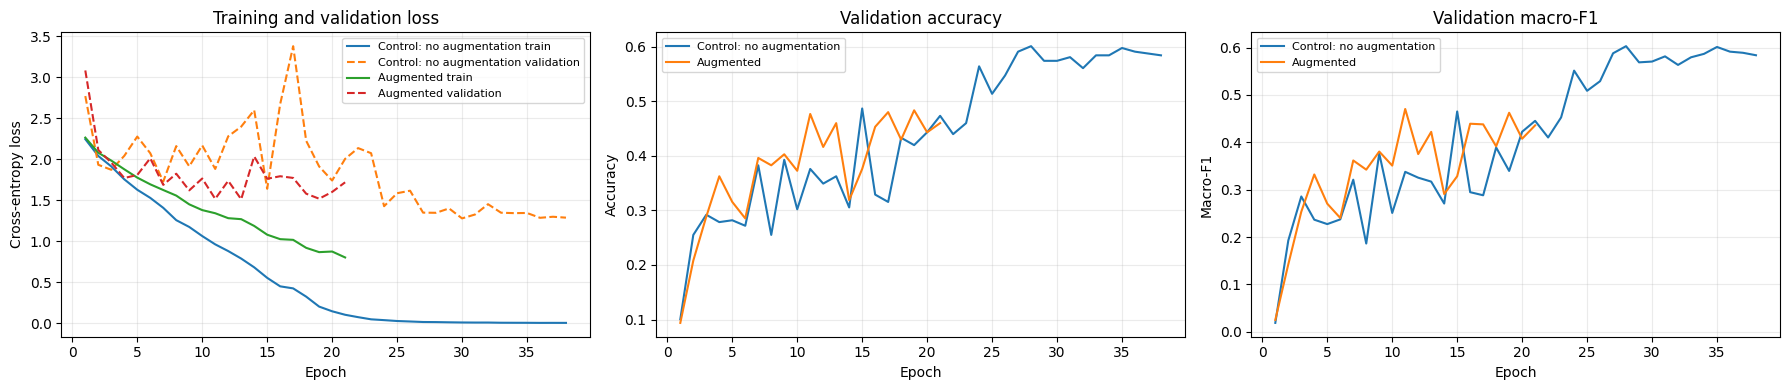

{
  "selection_split": "validation",
  "selection_metric": "macro-F1",
  "cnn_control_best_validation_macro_f1": 0.6028230719418188,
  "cnn_augmented_best_validation_macro_f1": 0.47024336197701666,
  "selected_model": "cnn_control",
  "selected_checkpoint": "outputs/cnn_control/best_model.pt"
}


In [ ]:
from pathlib import Path

reports_dir = Path("reports")
figures_dir = reports_dir / "figures"

reports_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)

comparison = {
    "selection_split": "validation",
    "selection_metric": "macro-F1",
    "cnn_control_best_validation_macro_f1": float(control_best_f1),
    "cnn_augmented_best_validation_macro_f1": float(augmented_best_f1),
    "selected_model": "cnn_control",
    "selected_checkpoint": "outputs/cnn_control/best_model.pt",
}

with open(reports_dir / "validation_model_comparison.json", "w") as file:
    json.dump(comparison, file, indent=2)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for history, name in [
    (control_history, "Control: no augmentation"),
    (augmented_history, "Augmented"),
]:
    epochs = [row["epoch"] for row in history]

    axes[0].plot(
        epochs,
        [row["train_loss"] for row in history],
        label=f"{name} train"
    )
    axes[0].plot(
        epochs,
        [row["validation_loss"] for row in history],
        linestyle="--",
        label=f"{name} validation"
    )

    axes[1].plot(
        epochs,
        [row["validation_accuracy"] for row in history],
        label=name
    )

    axes[2].plot(
        epochs,
        [row["validation_macro_f1"] for row in history],
        label=name
    )

axes[0].set_title("Training and validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")

axes[1].set_title("Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")

axes[2].set_title("Validation macro-F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro-F1")

for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)

plt.tight_layout()
plt.savefig(
    figures_dir / "validation_learning_curves.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

print(json.dumps(comparison, indent=2))

## 10. Final held-out test evaluation

The selected control CNN is evaluated once on the locked test split. Results are compared with the majority and logistic-regression baselines using accuracy, macro-F1, a confusion matrix, and misclassified-image examples.

/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(
/tmp/ipykernel_721/253880018.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(


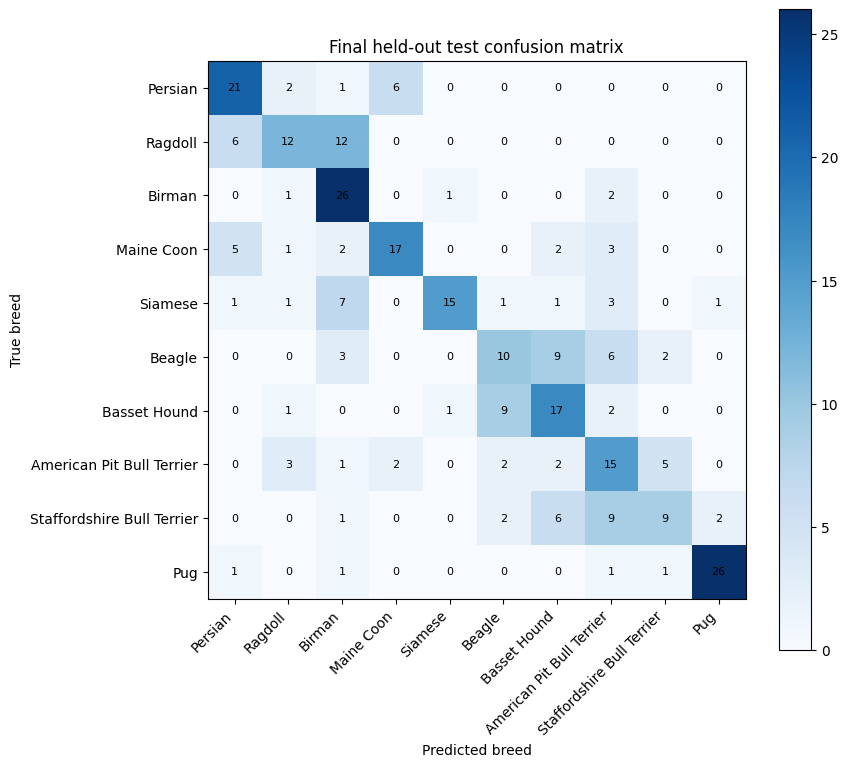

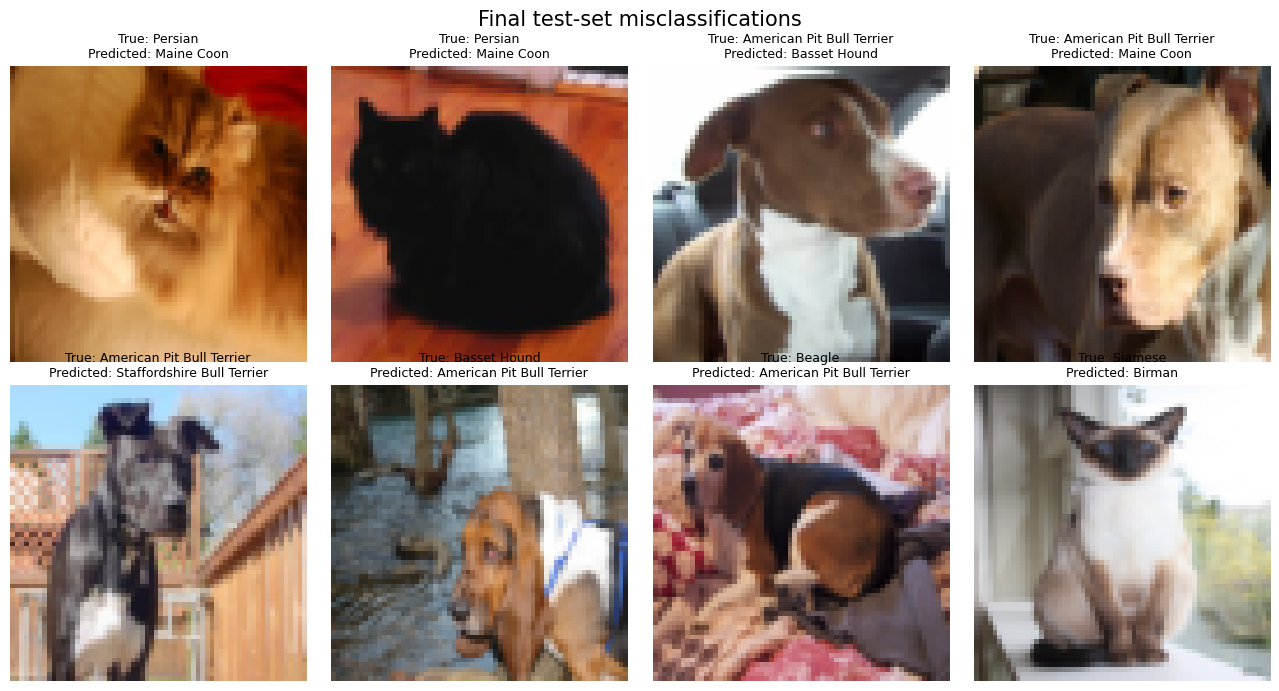

{
  "selection_rule": "Highest validation macro-F1",
  "selected_model": "cnn_control",
  "selected_epoch": 28,
  "majority_baseline": {
    "accuracy": 0.10033444816053512,
    "macro_f1": 0.0182370820668693
  },
  "logistic_regression": {
    "accuracy": 0.12374581939799331,
    "macro_f1": 0.12410954942188479
  },
  "custom_cnn": {
    "accuracy": 0.5618729096989966,
    "macro_f1": 0.5575394093098598
  },
  "class_names": [
    "Persian",
    "Ragdoll",
    "Birman",
    "Maine Coon",
    "Siamese",
    "Beagle",
    "Basset Hound",
    "American Pit Bull Terrier",
    "Staffordshire Bull Terrier",
    "Pug"
  ],
  "confusion_matrix": [
    [
      21,
      2,
      1,
      6,
      0,
      0,
      0,
      0,
      0,
      0
    ],
    [
      6,
      12,
      12,
      0,
      0,
      0,
      0,
      0,
      0,
      0
    ],
    [
      0,
      1,
      26,
      0,
      1,
      0,
      0,
      2,
      0,
      0
    ],
    [
      5,
      1,
      2,
      17

In [ ]:
from sklearn.metrics import confusion_matrix
from pathlib import Path

FINAL_RESULTS_PATH = Path("reports/final_test_results.json")

if FINAL_RESULTS_PATH.exists():
    raise RuntimeError(
        "Final test results already exist. Do not rerun or tune after test evaluation."
    )

selected_checkpoint_path = "outputs/cnn_control/best_model.pt"

checkpoint = torch.load(
    selected_checkpoint_path,
    map_location=device,
    weights_only=True
)

final_model = PetCNN(
    num_classes=len(BREEDS),
    dropout=checkpoint["dropout"]
).to(device)

final_model.load_state_dict(checkpoint["model_state_dict"])
final_model.eval()

test_predictions = []
test_targets = []

with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        batch_images = batch_images.to(device)

        logits = final_model(batch_images)
        predictions = logits.argmax(dim=1).cpu().numpy()

        test_predictions.extend(predictions)
        test_targets.extend(batch_labels.numpy())

test_predictions = np.asarray(test_predictions)
test_targets = np.asarray(test_targets)

# Majority-class baseline, derived from training labels only.
final_majority_class = np.bincount(labels[train_indices]).argmax()
final_majority_predictions = np.full(
    len(test_targets),
    final_majority_class
)

# Logistic-regression baseline, trained only on the training split.
all_image_tensor = torch.from_numpy(images).permute(
    0, 3, 1, 2
).float() / 255.0

all_gray_tensor = (
    0.299 * all_image_tensor[:, 0:1]
    + 0.587 * all_image_tensor[:, 1:2]
    + 0.114 * all_image_tensor[:, 2:3]
)

all_small_gray = F.interpolate(
    all_gray_tensor,
    size=(32, 32),
    mode="bilinear",
    align_corners=False
)

all_features = all_small_gray.flatten(start_dim=1).numpy()

final_logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED,
    n_jobs=-1
)

final_logistic_model.fit(
    all_features[train_indices],
    labels[train_indices]
)

final_logistic_predictions = final_logistic_model.predict(
    all_features[cache["test_indices"]]
)

cnn_test_accuracy = accuracy_score(test_targets, test_predictions)
cnn_test_f1 = f1_score(
    test_targets,
    test_predictions,
    average="macro",
    zero_division=0
)

majority_test_accuracy = accuracy_score(
    test_targets,
    final_majority_predictions
)

majority_test_f1 = f1_score(
    test_targets,
    final_majority_predictions,
    average="macro",
    zero_division=0
)

logistic_test_accuracy = accuracy_score(
    test_targets,
    final_logistic_predictions
)

logistic_test_f1 = f1_score(
    test_targets,
    final_logistic_predictions,
    average="macro",
    zero_division=0
)

test_confusion = confusion_matrix(
    test_targets,
    test_predictions,
    labels=range(len(BREEDS))
)

final_results = {
    "selection_rule": "Highest validation macro-F1",
    "selected_model": "cnn_control",
    "selected_epoch": int(checkpoint["epoch"]),
    "majority_baseline": {
        "accuracy": float(majority_test_accuracy),
        "macro_f1": float(majority_test_f1)
    },
    "logistic_regression": {
        "accuracy": float(logistic_test_accuracy),
        "macro_f1": float(logistic_test_f1)
    },
    "custom_cnn": {
        "accuracy": float(cnn_test_accuracy),
        "macro_f1": float(cnn_test_f1)
    },
    "class_names": BREEDS,
    "confusion_matrix": test_confusion.tolist()
}

with open(FINAL_RESULTS_PATH, "w") as file:
    json.dump(final_results, file, indent=2)

# Save a confusion-matrix figure.
plt.figure(figsize=(9, 8))
plt.imshow(test_confusion, cmap="Blues")
plt.colorbar()
plt.xticks(range(len(BREEDS)), BREEDS, rotation=45, ha="right")
plt.yticks(range(len(BREEDS)), BREEDS)
plt.xlabel("Predicted breed")
plt.ylabel("True breed")
plt.title("Final held-out test confusion matrix")

for row in range(len(BREEDS)):
    for column in range(len(BREEDS)):
        plt.text(
            column,
            row,
            test_confusion[row, column],
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.savefig(
    "reports/figures/final_test_confusion_matrix.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# Save eight real test-set mistakes for failure analysis.
incorrect_positions = np.where(
    test_predictions != test_targets
)[0]

rng = np.random.default_rng(SEED)
shown_positions = rng.choice(
    incorrect_positions,
    size=min(8, len(incorrect_positions)),
    replace=False
)

fig, axes = plt.subplots(2, 4, figsize=(13, 7))
axes = axes.flatten()

for axis in axes:
    axis.axis("off")

for axis, position in zip(axes, shown_positions):
    original_image_index = cache["test_indices"][position]

    axis.imshow(images[original_image_index])
    axis.set_title(
        f"True: {BREEDS[test_targets[position]]}\n"
        f"Predicted: {BREEDS[test_predictions[position]]}",
        fontsize=9
    )
    axis.axis("off")

plt.suptitle("Final test-set misclassifications", fontsize=15)
plt.tight_layout()
plt.savefig(
    "reports/figures/final_test_failures.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

print(json.dumps(final_results, indent=2))

## 11. Results and failure analysis

The CNN achieved 56.2% test accuracy and 55.8% test macro-F1, substantially exceeding both baselines. Typical errors include Ragdoll images predicted as Birman, Beagles confused with Basset Hounds, and Staffordshire Bull Terriers confused with American Pit Bull Terriers.